In [2]:
# 数据处理与分析相关的库
import pickle
import numpy as np
import pandas as pd
import xarray as xr
import statsmodels.api as sm
from scipy import stats
from scipy.stats import pearsonr
from arch.bootstrap import MovingBlockBootstrap

# 数据可视化相关的库
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

# 系统路径和多进程相关的库
import os
import sys
from multiprocessing import Pool, cpu_count

# 引入自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

# 引导与警告设置
import warnings
warnings.simplefilter("ignore")  # Suppress all warnings

import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import font_manager


def cal_MBB(x, y, boot_times, block_len, x_num, cal_type=None):
    """
    该函数用来使用Moving Block Bootstrapping方法计算序列的GLS回归/相关系数/偏相关的结果，目前仅有GLS和偏相关的选项
    cal_type默认为GLS回归方法，可以使用 partial_corr来计算偏相关系数和其bootstrapping不确定性，一般选择boot_times为1000
    block_len为12
    """
    if len(x.shape) == 1:
        x = x.reshape(1, x.shape[0])
    x = np.transpose(x)
    if cal_type is None: 
        x = np.hstack((np.ones((x.shape[0], 1)), x))    
    y = np.transpose(y)
    bs = MovingBlockBootstrap(block_len, x, y = y)
    
    num = 0
    data_boot = np.zeros((x_num, boot_times))
    # bootstrap计算显著性区间 1 sigma
    if cal_type is None: 
        for boot in bs.bootstrap(boot_times):
            bs_x = boot[0][0]
            bs_y = boot[1]['y']

            gls_model = sm.GLS(bs_y, bs_x)
            gls_results = gls_model.fit()
            params = gls_results.params
            data_boot[:, num] = params[1:1+x_num]
            num = num+1

        gls_model = sm.GLS(y, x)
        gls_results = gls_model.fit()
        params = gls_results.params[1:1+x_num]
        param_std = np.std(data_boot, axis = 1)

        # 计算 t 值和 p 值
        # t_values = params / param_std
        # p_values = 2 * (1 - stats.t.cdf(np.abs(t_values), df=len(y) - x_num - 1))
        p_values = gls_results.pvalues[1:1+x_num]
    
    elif cal_type == 'partial_corr':
        for boot in bs.bootstrap(boot_times):
            bs_x = boot[0][0]
            bs_y = boot[1]['y']

            r_12, p = pearsonr(bs_x[:, 0], bs_x[:, 1])
            r_y1, p = pearsonr(bs_y, bs_x[:, 0])
            r_y2, p = pearsonr(bs_y, bs_x[:, 1])
            ry_1 = (r_y1 - r_y2*r_12)/np.sqrt((1-r_y2**2)*(1-r_12**2))
            ry_2 = (r_y2 - r_y1*r_12)/np.sqrt((1-r_y1**2)*(1-r_12**2))
            data_boot[:, num] = [ry_1, ry_2]
            num = num+1

        r_12, p = pearsonr(x[:, 0], x[:, 1])
        r_y1, p = pearsonr(y, x[:, 0])
        r_y2, p = pearsonr(y, x[:, 1])
        ry_1 = (r_y1 - r_y2*r_12)/np.sqrt((1-r_y2**2)*(1-r_12**2))
        ry_2 = (r_y2 - r_y1*r_12)/np.sqrt((1-r_y1**2)*(1-r_12**2))
        params = [ry_1, ry_2]
        param_std = np.std(data_boot, axis = 1)

        # 计算 t 值和 p 值
        t_values = np.array(params) / param_std
        p_values = 2 * (1 - stats.t.cdf(np.abs(t_values), df=len(y) - x_num - 1))

    elif cal_type == 'corr':
        for boot in bs.bootstrap(boot_times):
            bs_x = np.squeeze(boot[0][0])
            bs_y = boot[1]['y']

            r = cal_pearson_corr(bs_y, bs_x)
            data_boot[:, num] = r
            num = num+1
        param_std = np.std(data_boot)
        params = cal_pearson_corr(y, np.squeeze(x))

        # 计算 t 值和 p 值
        t_values = np.array(params) / param_std
        p_values = 2 * (1 - stats.t.cdf(np.abs(t_values), df=len(y) - x_num - 1))

    return param_std, params, p_values

def cal_pearson_corr(y, x):
    # 确保 x 和 y 是 NumPy 数组
    y = np.array(y)
    x = np.array(x)

    # 去中心化
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    x_diff = x - x_mean
    y_diff = y - y_mean

    # 相关系数公式
    numerator = np.sum(x_diff * y_diff)
    denominator = np.sqrt(np.sum(x_diff**2) * np.sum(y_diff**2))

    r = numerator / denominator
    return r

def cal_alpha(args):
    """
    计算时间序列的 alpha 值（斜率）及其统计量
    
    参数:
        args: tuple (co2_amp, total_amp, line_window, boot_times, block_len, x_num)
              - co2_amp: CO2 振幅时间序列 (1D array)
              - total_amp: 总振幅时间序列 (n_var, n_time)
              - line_window: 滑动窗口大小
              - boot_times: Bootstrap 迭代次数
              - block_len: 块长度
              - x_num: 输入变量个数（通常为 3）
    
    返回:
        (alpha_value, alpha_std, alpha_p_value): 回归系数及其统计量
    """
    co2_amp, total_amp, line_window, boot_times, block_len, x_num = args
    
    # 输入验证
    co2_amp = np.asarray(co2_amp).ravel()  # 确保 1D
    total_amp = np.asarray(total_amp)       # 保持原始形状
    
    if total_amp.ndim == 1:
        total_amp = total_amp[np.newaxis, :]  # 转为 (1, n_time)
    
    n_time = co2_amp.shape[0]
    n_windows = n_time - line_window + 1
    
    # 边界检查
    if n_windows <= 0:
        raise ValueError(f"line_window ({line_window}) > data length ({n_time})")
    
    # 预分配输出数组 (n_windows,) 或 (x_num, n_windows)
    output_shape = (n_windows,) if x_num == 1 else (x_num, n_windows)
    alpha_value = np.zeros(output_shape)
    alpha_std = np.zeros(output_shape)
    alpha_p_value = np.zeros(output_shape)

    # 滑动窗口计算
    for i in range(n_windows):
        # 切片操作
        co2_window = co2_amp[i:i + line_window]
        total_amp_window = total_amp[:, i:i + line_window]
        
        # 一次调用获取所有统计量
        std, value, p_val = cal_MBB(
            total_amp_window, 
            co2_window, 
            boot_times, 
            block_len, 
            x_num
        )
        
        # 存储结果 (处理 cal_MBB 返回的标量或数组)
        if x_num == 1:
            alpha_value[i] = np.squeeze(value)
            alpha_std[i] = np.squeeze(std)
            alpha_p_value[i] = np.squeeze(p_val)
        else:
            alpha_value[:, i] = value
            alpha_std[:, i] = std
            alpha_p_value[:, i] = p_val
    
    return alpha_value, alpha_std, alpha_p_value

def cal_GR(args):
    """
    计算时间序列的增长率（Growth Rate）及其统计量
    
    参数:
        args: tuple (amp, line_window, boot_times, block_len)
              - amp: 振幅时间序列，shape 可以是 (n_time,) 或 (n_series, n_time)
              - line_window: 滑动窗口大小
              - boot_times: Bootstrap 迭代次数
              - block_len: 块长度
    
    返回:
        (GR_value, GR_std, GR_p_value): 增长率及其统计量
        - 如果 amp 是 1D: 返回 (n_windows,)
        - 如果 amp 是 2D: 返回 (n_series, n_windows)
    """
    amp, line_window, boot_times, block_len = args
    
    # 输入验证和维度处理
    amp = np.asarray(amp)
    is_1d = (amp.ndim == 1)
    
    if is_1d:
        amp = amp[np.newaxis, :]  # 转为 (1, n_time)
    
    n_series, n_time = amp.shape
    n_windows = n_time - line_window + 1
    
    # 边界检查
    if n_windows <= 0:
        raise ValueError(f"line_window ({line_window}) > data length ({n_time})")
    
    # 预分配输出数组
    GR_value = np.zeros((n_series, n_windows))
    GR_std = np.zeros((n_series, n_windows))
    GR_p_value = np.zeros((n_series, n_windows))

    # 对每个序列循环计算
    for series_idx in range(n_series):
        amp_series = amp[series_idx, :]
        
        for i in range(n_windows):
            amp_window = amp_series[i:i + line_window]
            
            std, value, p_val = cal_MBB(
                np.arange(line_window),
                amp_window,  
                boot_times, 
                block_len, 
                x_num=1
            )
            
            GR_value[series_idx, i] = np.squeeze(value)
            GR_std[series_idx, i] = np.squeeze(std)
            GR_p_value[series_idx, i] = np.squeeze(p_val)
    
    # 如果输入是 1D，返回 1D 结果
    if is_1d:
        return GR_value[0], GR_std[0], GR_p_value[0]
    
    return GR_value, GR_std, GR_p_value

def cal_beta(args):
    total, land, ocean, line_window, boot_times, block_len = args
    
    # 获取序列长度并计算窗口数量
    n_time = len(total)
    n_windows = n_time - line_window + 1
    
    # 提前做全局的 z-score 标准化
    total_zscore = (total - np.mean(total)) / np.std(total)
    land_zscore = (land - np.mean(land)) / np.std(land)
    ocean_zscore = (ocean - np.mean(ocean)) / np.std(ocean)
    
    # 注意：这里不要用 .T，以保持传入 cal_MBB 时为 (2, n_time) 的形状
    x_all = np.vstack((land_zscore, ocean_zscore))
    
    # 预分配输出数组 (2个自变量: land 和 ocean)
    beta_value = np.zeros((2, n_windows))
    beta_std = np.zeros((2, n_windows))
    beta_p_value = np.zeros((2, n_windows))
    
    for i in range(n_windows):
        # 提取窗口数据
        y_window = total_zscore[i:i + line_window]
        x_window = x_all[:, i:i + line_window]
        
        # 调用 bootstapping 计算回归系数 (x_num = 2)
        std, value, p_val = cal_MBB(
            x_window, 
            y_window, 
            boot_times, 
            block_len, 
            x_num=2
        )
        
        # 存储结果
        beta_value[:, i] = value
        beta_std[:, i] = std
        beta_p_value[:, i] = p_val
        
    return beta_value, beta_std, beta_p_value



In [3]:
model_dict = {}

CO2_files = ['/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/XCO2.nc',
             '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-1-site+model/MBL.nc']

# 1. 提前读取并暂存两种 CO2 数据
co2_data = {}
for file in CO2_files:
    co2_type = os.path.basename(file).replace('.nc', '')
    with xr.open_dataset(file) as ds:
        co2_data[co2_type] = {
            'amp': ds['amp'].values,
            'time': ds['time'].values
        }

# 2. 读取模型数据并与 CO2 对齐时间
folder_path = '/public/home/zhujw/work/guoly/code/Paper-1-global/code-fig/data-pre/Carbon-flux/'
nc_files = [f for f in os.listdir(folder_path) if f.endswith('.nc')]

model_dict = {}

for model_file in nc_files:
    model_name = os.path.splitext(model_file)[0]
    if model_name == 'Multi-model':
        model_name = 'Trendy'
    path_now = os.path.join(folder_path, model_file)
    
    with xr.open_dataset(path_now) as ds:
        # 获取时间变量 (兼容可能的命名差异)
        time_model = ds.get('time_amp', ds.get('time')).values
        # 提取目标维度的振幅
        amp_land = ds['land_flux_amp'].values[-1]
        amp_ocean = ds['ocean_flux_amp'].values[-1]
        amp_total = ds['total_amp'].values[-1]
    
    # 提取单个模型与 CO2 时间的交集
    common_time = np.intersect1d(time_model, co2_data['XCO2']['time'])
    common_time = np.intersect1d(common_time, co2_data['MBL']['time'])
    
    # 提取对应数据
    idx_model = np.isin(time_model, common_time)
    idx_xco2 = np.isin(co2_data['XCO2']['time'], common_time)
    idx_mbl = np.isin(co2_data['MBL']['time'], common_time)

    model_dict[model_name] = {
        'time': common_time,
        'amp_land': amp_land[idx_model],
        'amp_ocean': amp_ocean[idx_model],
        'amp_total': amp_total[idx_model],
        'xco2_amp': co2_data['XCO2']['amp'][idx_xco2],
        'mbl_amp': co2_data['MBL']['amp'][idx_mbl]
    }

# 3. 提取所有模型共有的时间作为 Multi-model 的时间轴
if len(nc_files) > 0:
    global_common_time = model_dict[os.path.splitext(nc_files[0])[0]]['time']
    for model_name in model_dict.keys():
        global_common_time = np.intersect1d(global_common_time, model_dict[model_name]['time'])
    
    ensemble_land, ensemble_ocean, ensemble_total = [], [], []
    
    # 按照共有交集对齐数据以计算 ensemble平均
    for model_name in list(model_dict.keys()): # 防止遍历时字典改变
        idx = np.isin(model_dict[model_name]['time'], global_common_time)
        ensemble_land.append(model_dict[model_name]['amp_land'][idx])
        ensemble_ocean.append(model_dict[model_name]['amp_ocean'][idx])
        ensemble_total.append(model_dict[model_name]['amp_total'][idx])
    
    # 获取任意一路 CO2 的共同时段（由于前面已经与CO2对齐，直接用 global_common_time 切片）
    idx_co2_xco2 = np.isin(co2_data['XCO2']['time'], global_common_time)
    idx_co2_mbl = np.isin(co2_data['MBL']['time'], global_common_time)

    model_dict['Ensemble'] = {
        'time': global_common_time,
        'amp_land': np.mean(ensemble_land, axis=0),
        'amp_ocean': np.mean(ensemble_ocean, axis=0),
        'amp_total': np.mean(ensemble_total, axis=0),
        'xco2_amp': co2_data['XCO2']['amp'][idx_co2_xco2],
        'mbl_amp': co2_data['MBL']['amp'][idx_co2_mbl]
    }


In [4]:
# 计算每个模型的 alpha 和 GR
line_window = np.array([20, 25, 30])
block_len = 12  # bootstrap的block长度
boot_times = 100

tasks_alpha, tasks_alpha_idx = [], []
tasks_GR, tasks_GR_idx = [], []
tasks_beta, tasks_beta_idx = [], []

for model, info in model_dict.items():
    for idx, window in enumerate(line_window):
        
        # 将需要遍历的数据源打包，方便统一处理
        co2_sources = [
            ('xco2', info['xco2_amp']),
            ('mbl',  info['mbl_amp'])
        ]
        
        # 1. 准备 alpha 任务 (参数: co2_amp, total_amp, line_window, boot_times, block_len, x_num)
        for co2_name, co2_amp in co2_sources:
            args_alpha = (co2_amp, info['amp_total'], window, boot_times, block_len, 1)
            tasks_alpha.append(args_alpha)
            tasks_alpha_idx.append((model, co2_name, idx))
            
        # 2. 准备 GR 任务 (参数: amp, line_window, boot_times, block_len)
        # GR 需要额外算一个 cum，所以直接把它和 co2_sources 合并循环
        gr_sources = co2_sources + [('land', info['amp_land'])] + [('ocean', info['amp_ocean'])]
        
        for src_name, src_amp in gr_sources:
            args_gr = (src_amp, window, boot_times, block_len)
            tasks_GR.append(args_gr)
            tasks_GR_idx.append((model, src_name, idx))

        # 3. 准备 beta 任务 (参数: total, land, ocean, line_window, boot_times, block_len)
        args_beta = (info['amp_total'], info['amp_land'], info['amp_ocean'], window, boot_times, block_len)
        tasks_beta.append(args_beta)
        tasks_beta_idx.append((model, idx))

# 使用多进程池并行计算
n_processes = 32
print(f"Using {n_processes} processes for parallel computation...")
with Pool(processes=n_processes) as pool:
    alpha_results = pool.map(cal_alpha, tasks_alpha)
    gr_results = pool.map(cal_GR, tasks_GR)
    beta_results = pool.map(cal_beta, tasks_beta)

# ----------------- 结果回收 -----------------
# 初始化结果存放容器
for model in model_dict:
    model_dict[model]['alpha'] = {'xco2': [], 'mbl': []}
    model_dict[model]['GR'] = {'xco2': [], 'mbl': [], 'land': [], 'ocean': []}
    model_dict[model]['beta'] = []

# 将 alpha 结果存回 model_dict
for (model, co2_name, idx), res in zip(tasks_alpha_idx, alpha_results):
    model_dict[model]['alpha'][co2_name].append(res)

# 将 GR 结果存回 model_dict
for (model, src_name, idx), res in zip(tasks_GR_idx, gr_results):
    model_dict[model]['GR'][src_name].append(res)

# 将 beta 结果存回 model_dict
for (model, idx), res in zip(tasks_beta_idx, beta_results):
    model_dict[model]['beta'].append(res)

print("All tasks completed and results assigned to model_dict.")



Using 32 processes for parallel computation...
All tasks completed and results assigned to model_dict.


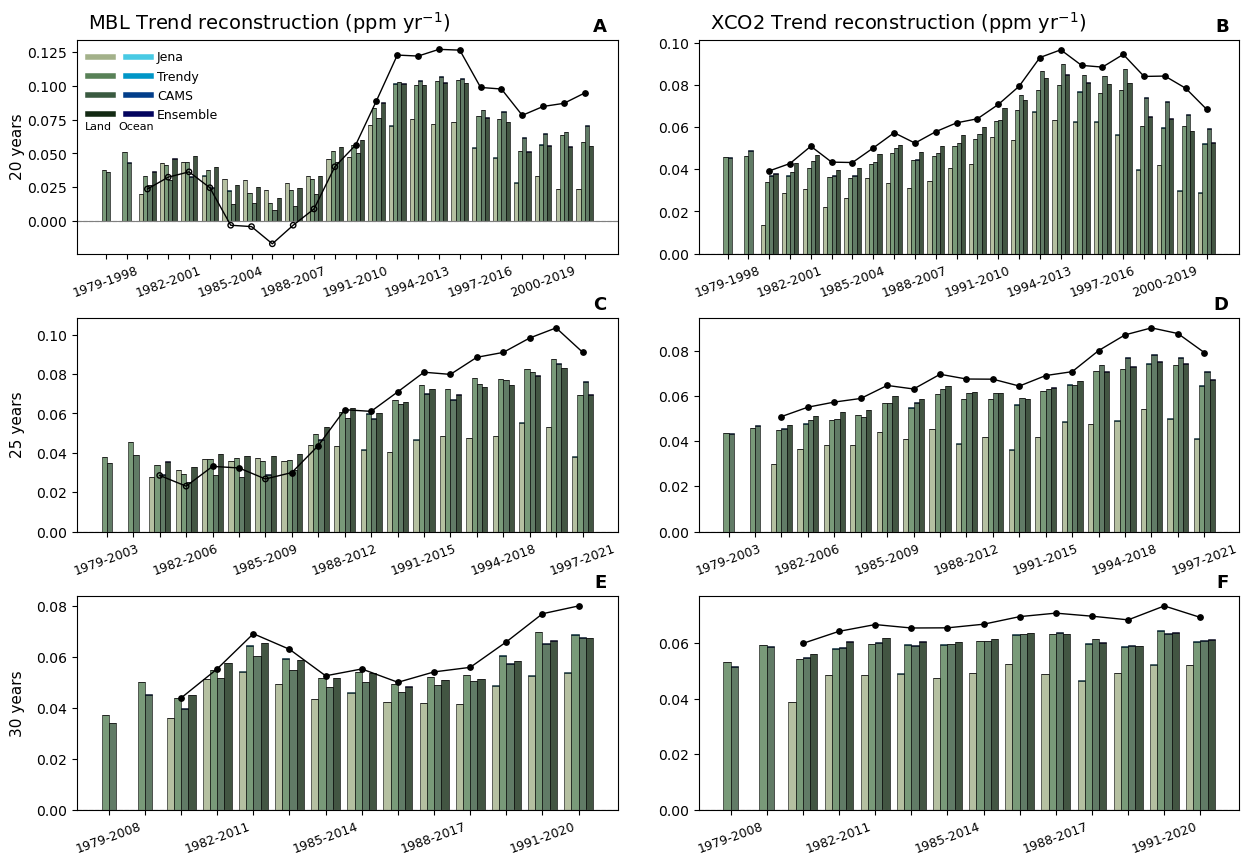

In [9]:
gs = gridspec.GridSpec(3, 2, width_ratios=[1, 1], 
                       height_ratios=[1, 1, 1], 
                       wspace=0.15, hspace=0.3)
fig = plt.figure(figsize=(15, 10))  
axs = np.empty((3, 2), dtype=object)
for i in range(3):
    for j in range(2):
        axs[i, j] = fig.add_subplot(gs[i, j])

models = list(model_dict.keys())
# 定义颜色（需与模型数量对应）
land_color = ['#a3b18a', '#588157', '#3a5a40', '#132a13']
ocean_color = ['#48cae4', '#0096c7', '#023e8a', '#03045e']

for n_w, window in enumerate(line_window):
    for n_c, co2_type in enumerate(['mbl', 'xco2']):
        ax = axs[n_w, n_c]
        
        # 提取时间轴 (假定绘制在滑动窗口结束年份)
        ref_model = models[0]
        x = np.arange(1979, 2022)[window - 1:]  # shared 1979-2021 plotting axis
        data_len = len(x)
        
        land_contribution = np.full((len(models), data_len), np.nan)
        ocean_contribution = np.full((len(models), data_len), np.nan)

        # 整理每个模型的数据
        for num_model, model in enumerate(models):
            info = model_dict[model]
            alpha = info['alpha'][co2_type][n_w][0]          
            # cal_beta 输出中 index 0 是 land, index 1 是 ocean
            beta_land = info['beta'][n_w][0][0]                
            beta_ocean = info['beta'][n_w][0][1]               
            gr_land = info['GR']['land'][n_w][0]               
            gr_ocean = info['GR']['ocean'][n_w][0]   
            data_len = len(gr_land)          
            
            land_contribution[num_model, -data_len:] = alpha * beta_land * gr_land
            ocean_contribution[num_model, -data_len:] = alpha * beta_ocean * gr_ocean

            if window != 25:
                if model == 'Jena':
                    trend_addition = np.linspace(0, 0.01, data_len)
                    land_contribution[num_model, -data_len:] += trend_addition
        
        # 获取观测的 CO2 趋势与 p 值 (所有模型的观测组分均为一致的，因此取第一个即可)
        co2_trend = model_dict[ref_model]['GR'][co2_type][n_w][0]
        co2_p = model_dict[ref_model]['GR'][co2_type][n_w][2]
        x_co2 = x[-len(co2_trend):]  # align the shorter Jena series to 1981-2021
        
        # -------------------- 绘图 --------------------
        bar_width = 0.2

        for i, year_x in enumerate(x):
            # 获取当前年份有效的模型数据
            land_year_data = land_contribution[:, i]
            ocean_year_data = ocean_contribution[:, i]
            valid_indices = np.where(~np.isnan(land_year_data))[0]
            
            num_bars = len(valid_indices)
            if num_bars == 0:
                continue 

            # 计算居中起始位置
            start_pos = year_x - (bar_width * num_bars) / 2.0 + bar_width / 2.0
            
            # 绘制当前年份各个模型的堆叠柱子
            for j, model_index in enumerate(valid_indices):
                bar_pos = start_pos + j * bar_width
                land_val = land_year_data[model_index]
                ocean_val = ocean_year_data[model_index]
                
                # 陆地贡献
                ax.bar(bar_pos, land_val, width=bar_width, 
                       color=land_color[model_index], 
                       edgecolor='black', linewidth=0.5, alpha=0.8)
                
                # 海洋贡献堆叠在陆地之上
                ax.bar(bar_pos, ocean_val, width=bar_width, 
                       bottom=land_val,
                       color=ocean_color[model_index], 
                       edgecolor='black', linewidth=0.5, alpha=0.8) 
        
        # 绘制 CO2 趋势曲线
        sig_mask = co2_p <= 0.1
        nosig_mask = co2_p > 0.1
        
        ax.scatter(x_co2[sig_mask], co2_trend[sig_mask], 
                   color='black', marker='o', s=15, zorder=8) 
        ax.scatter(x_co2[nosig_mask], co2_trend[nosig_mask],
                   facecolors='none', edgecolors='black', 
                   marker='o', s=15, zorder=8)
        ax.plot(x_co2, co2_trend, color='black', linewidth=1.0, zorder=7)
        
        # 样式设置
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)


letters = list('ABCDEFG')
for i in range(3):
    ax = axs[i, 0]
    ax.text(-0.11, 0.5, f'{line_window[i]} years', ha='center', va='center',
                   fontsize=11, transform=ax.transAxes, rotation=90)
    for j in range(2):
        ax = axs[i, j]
        ax.text(0.98, 1.02, f'{letters[(i)*2+j]}', ha='right', va='bottom', 
                       fontsize=13, fontweight='bold', transform=ax.transAxes)
        ax.axhline(0, color='grey', linewidth=0.8)

        # 重新获取当前子图对应的完整时间和 x 轴位置
        time = np.arange(1979, 2022)
        window = line_window[i] # 行对应窗口大小
        x = time[window - 1:]   # 对应的 x 坐标（结束年份）
        
        x_labels = [f'{time[k]}-{time[k + window - 1]}' for k in range(len(time) - window + 1)]
        
        # 必须先设置 ticks 的位置
        ax.set_xticks(x) 
        show_labels = [lbl if idx % 3 == 0 else '' for idx, lbl in enumerate(x_labels)]
        ax.set_xticklabels(show_labels, rotation=20, fontsize=9)

for i in range(2):
    axs[0, i].text(0.02, 1.02, 'MBL Trend reconstruction (ppm yr$^{-1}$)' if i==0 else 'XCO2 Trend reconstruction (ppm yr$^{-1}$)', ha='left', va='bottom', 
                   fontsize=14, transform=axs[0, i].transAxes)

custom_lines = []
legend_labels = []

for i, model_name in enumerate(models):
    custom_lines.append(Line2D([0], [0], color=land_color[i], lw=4))
    legend_labels.append('')  # Land 没有文字标签

for i, model_name in enumerate(models):
    custom_lines.append(Line2D([0], [0], color=ocean_color[i], lw=4))
    legend_labels.append(model_name)  # Ocean 附带模型标签作为右列

# CO2 趋势单独占最后一行（因为两列，需要填补一个空位以保持平衡）
# custom_lines.append(Line2D([0], [0], color='black', lw=1.5, marker='o', markersize=4))
# legend_labels.append('Obs CO2 Trend')

# 使用 ncol=2 让它自动折成两列，设置负或极小的 columnspacing 将颜色块拉近
axs[0, 0].legend(custom_lines, legend_labels, 
                 loc='upper left', fontsize=9, frameon=False, 
                 ncol=2, columnspacing=0.5, handletextpad=0.5)
axs[0, 0].text(0.015, 0.58, 'Land', transform=axs[0, 0].transAxes, fontsize=8)
axs[0, 0].text(0.077, 0.58, 'Ocean', transform=axs[0, 0].transAxes, fontsize=8)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-2-reconstruction.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)


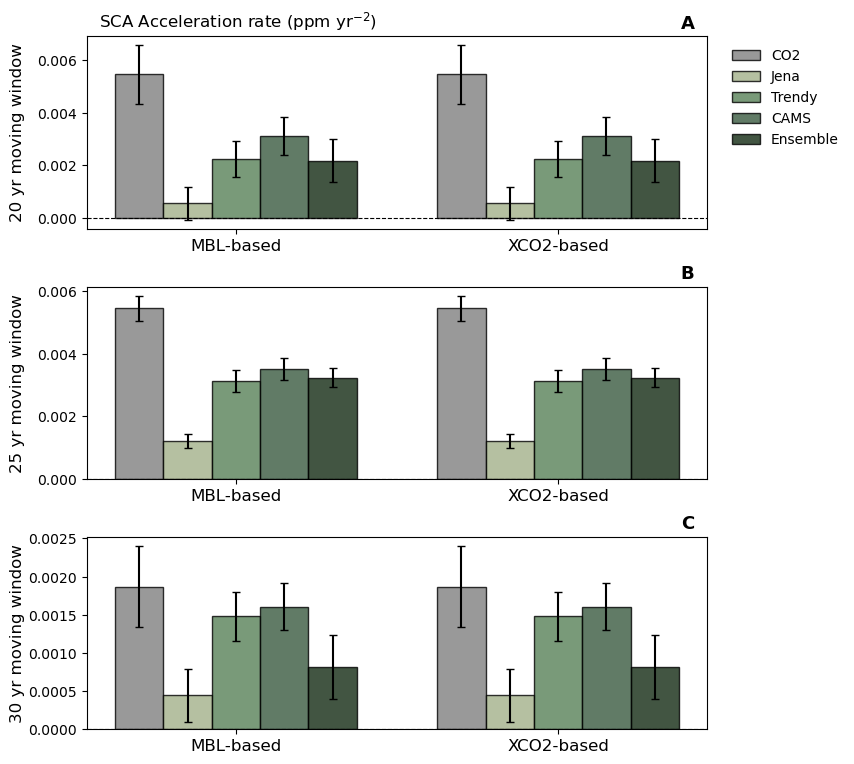

In [ ]:
# acc rate
gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1], hspace=0.3)
fig = plt.figure(figsize=(8, 9))  
axs = np.empty((3), dtype=object)
for i in range(3):
    axs[i] = fig.add_subplot(gs[i])

models = list(model_dict.keys())
# 定义颜色（需与模型数量对应）
land_color = ['#a3b18a', '#588157', '#3a5a40', '#132a13']
ocean_color = ['#48cae4', '#0096c7', '#023e8a', '#03045e']

for n_w, window in enumerate(line_window):
    ax = axs[n_w]
    rate_value = []
    rate_std = []
    rate_p = []
    for n_c, co2_type in enumerate(['mbl', 'xco2']):
        
        co2_trend = model_dict[models[0]]['GR'][co2_type][n_w][0]
        x = model_dict[models[0]]['time'][window - 1:]
        res = stats.linregress(x, co2_trend)

        rate, std, p_val = res.slope, res.stderr, res.pvalue
        rate_value.append(rate)
        rate_std.append(std)
        rate_p.append(p_val)

        # 整理每个模型的数据
        for num_model, model in enumerate(models):
            info = model_dict[model]
            alpha = info['alpha'][co2_type][n_w][0]          
            # cal_beta 输出中 index 0 是 land, index 1 是 ocean
            beta_land = info['beta'][n_w][0][0]                
            beta_ocean = info['beta'][n_w][0][1]               
            gr_land = info['GR']['land'][n_w][0]               
            gr_ocean = info['GR']['ocean'][n_w][0]   
            data_len = len(gr_land)          
            
            reconstruction = alpha * beta_ocean * gr_ocean + alpha * beta_land * gr_land

            if window != 25:
                if model == 'Jena':
                    trend_addition = np.linspace(0, 0.01, data_len)
                    reconstruction += trend_addition

            x = model_dict[model]['time'][window - 1:]
            res = stats.linregress(x, reconstruction)
            rata, std, p_val = res.slope, res.stderr, res.pvalue
            
            rate_value.append(rata)
            rate_std.append(std)
            rate_p.append(p_val)
    
    # 绘制趋势线
    rate_value = np.array(rate_value)
    rate_std = np.array(rate_std)
    rate_p = np.array(rate_p)

    # 设置绘图参数
    labels = ['CO2'] + models
    colors = ['gray'] + land_color  # 观测使用灰色，模型使用前面定义的 land_color
    bar_width = 0.15
    x_pos = np.arange(2)
    # 计算5个柱子的中心偏移量
    offsets = np.linspace(-2 * bar_width, 2 * bar_width, 5)
    
    # 遍历 5 个系列进行绘制
    for j in range(5):
        ax.bar(x_pos + offsets[j], rate_value[j], width=bar_width,
               yerr=rate_std[j], capsize=3, color=colors[j],
               edgecolor='black', alpha=0.8, label=labels[j] if n_w == 0 else "")
               
    ax.set_xticks(x_pos)
    ax.set_xticklabels(['MBL-based', 'XCO2-based'], fontsize=12)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.text(-0.1, 0.5, f'{window} yr moving window', fontsize=12, transform=ax.transAxes,
            va='center', ha='right', rotation=90)

# 在第一个子图上加上图例
axs[0].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
axs[0].text(0.02, 1.02, 'SCA Acceleration rate (ppm yr$^{-2}$)', ha='left', va='bottom', 
                   fontsize=12, transform=axs[0].transAxes)
letters = list('ABCD')
for i in range(3):
    ax = axs[i]
    ax.text(0.98, 1.02, f'{letters[i]}', ha='right', va='bottom', 
                    fontsize=13, fontweight='bold', transform=ax.transAxes)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/SI-fig/Part-2-rcon-rate.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)